# 04. Transfer learning

Беремо готові моделі, попередньо навчені на ImageNet (мільйони звичайних фотографій), і донавчаємо їх на рентгенах. Така мережа вже вміє бачити краї, текстури й форми, тому їй потрібно менше даних.

1. Підготовка знімків 224 × 224 під вимоги готових моделей.
2. Побудова моделей у двох режимах: «заморожена» і fine-tuning.
3. Функція навчання з ранньою зупинкою.
4. Три експерименти: ResNet18 заморожена, ResNet18 fine-tuning, DenseNet121 fine-tuning.
5. Порівняння з notebooks 02 і 03 в одній таблиці.

### 1) Імпорти, шляхи, seed, пристрій

Підключаємо бібліотеки, шляхи і `SEED = 42`. Вибираємо пристрій (GPU або CPU). Додатково імпортуємо `roc_auc_score` і готові моделі з `torchvision`.

In [1]:
import copy
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from torchvision import transforms as T

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)

DATA_DIR = Path("../data/chest_xray")
RESULTS_DIR = Path("../results")
SEED = 42

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Пристрій:", device)

def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

Пристрій: cpu


### 2) Завантаження даних

Готові мережі навчались на великих зображеннях, тому для них використовуємо розмір 224 × 224 (в notebooks 02 і 03 було 128 × 128). Знімки переводимо в чорно-білі, зменшуємо і зберігаємо в кеш `cache_224.npz`, щоб не робити це щоразу. Потім створюємо маски train/val/test.

In [ ]:
df = pd.read_csv(RESULTS_DIR / "splits.csv")
df["y"] = (df["label"] == "PNEUMONIA").astype(int)

TF_SIZE = 224
cache_tf = DATA_DIR.parent / f"cache_{TF_SIZE}.npz"

def load_image(r):
    img = Image.open(DATA_DIR / r.split / r.label / r.filename)
    img = img.convert("L").resize((TF_SIZE, TF_SIZE))
    return np.asarray(img, dtype=np.uint8)

if cache_tf.exists():
    X_img = np.load(cache_tf)["X"]
    print("Завантажено з кешу")
else:
    X_img = np.stack([load_image(r) for r in tqdm(df.itertuples(), total=len(df))])
    np.savez_compressed(cache_tf, X=X_img)

assert len(X_img) == len(df)

tr = (df["new_split"] == "train").values
va = (df["new_split"] == "val").values
te = (df["new_split"] == "test").values
y = df["y"].values

print(X_img.shape, "| train:", tr.sum(), "| val:", va.sum(), "| test:", te.sum())

100%|██████████| 5856/5856 [00:28<00:00, 206.07it/s]


(5856, 224, 224) | train: 4160 | val: 1072 | test: 624


Розбиття те саме: 4 160 / 1 072 / 624, тільки знімки тепер 224 × 224.

### 3) Аугментація і датасет

Аугментація та сама, що в notebook 03: невеликі поворот, зсув, масштаб, зміна яскравості і контрасту (тільки для train).

Готові мережі чекають трьоканальне кольорове зображення, нормоване так, як на ImageNet. Тому `XrayDatasetTF` копіює чорно-білий канал тричі (`repeat(3, 1, 1)`) і віднімає середнє та ділить на стандартне відхилення ImageNet. Без цього попередньо навчені ваги працювали б гірше.

In [ ]:
augment_tf = T.Compose([
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.2, contrast=0.2),
])

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class XrayDatasetTF(Dataset):
    def __init__(self, X, y, transform=None):
        self.X, self.y, self.transform = X, y, transform

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i]).float().div(255).unsqueeze(0)
        if self.transform is not None:
            x = self.transform(x)
        x = x.repeat(3, 1, 1) 
        x = (x - IMAGENET_MEAN) / IMAGENET_STD 
        return x, torch.tensor(self.y[i], dtype=torch.float32)

### 4) Побудова моделей

`build_model` завантажує модель з вагами ImageNet і замінює останній шар на новий: `Dropout(0.3)` і один вихідний нейрон (ймовірність пневмонії). Старий шар відкидаємо, бо він передбачав 1000 класів ImageNet.

Далі вирішуємо, які ваги навчати:

- **frozen (заморожена):** всі ваги, крім нового шару, заморожуємо (`requires_grad = False`). Навчається лише класифікатор поверх готових ознак.
- **finetune:** додатково розморожуємо останні блоки (`layer4` у ResNet18, `denseblock4` і `norm5` у DenseNet121). Вони відповідають за найскладніші ознаки, тому їх варто підлаштувати під рентген, а ранні шари (краї, текстури) залишаємо як є.

`set_train_mode` переводить у режим оцінювання ті шари `BatchNorm`, що заморожені. Інакше вони б змінювали свою статистику на наших даних, хоча решта мережі заморожена.

Для замороженої ResNet18 навчається лише 513 параметрів із понад 11 мільйонів.

In [ ]:
def build_model(arch, mode):
    if arch == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 1))
        head = m.fc
        last_blocks = [m.layer4]
    elif arch == "densenet121":
        m = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
        m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(1024, 1))
        head = m.classifier
        last_blocks = [m.features.denseblock4, m.features.norm5]
    else:
        raise ValueError(arch)

    for p in m.parameters():  
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    if mode == "finetune": 
        for blk in last_blocks:
            for p in blk.parameters():
                p.requires_grad = True
    return m, head

def set_train_mode(model):
    model.train()
    for mod in model.modules():
        if isinstance(mod, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in mod.parameters()):
            mod.eval()

m, _ = build_model("resnet18", "frozen")
print("Навчається параметрів:", sum(p.numel() for p in m.parameters() if p.requires_grad),
      "з", sum(p.numel() for p in m.parameters()))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Адмін/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:12<00:00, 3.77MB/s]

Навчається параметрів: 513 з 11177025


### 5) Передбачення і метрики

`predict` і `compute_metrics` працюють так само, як у notebook 03, але додатково рахуємо **AUC** (площу під ROC-кривою). Вона оцінює, наскільки добре ймовірності розділяють класи за будь-якого порогу, тому не залежить від вибору порога 0,5.

In [6]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    for xb, yb in loader:
        probs.append(torch.sigmoid(model(xb.to(device)).squeeze(1)).cpu().numpy())
        ys.append(yb.numpy())
    return np.concatenate(probs), np.concatenate(ys).astype(int)

def compute_metrics(y_true, probs, threshold=0.5):
    pred = (probs >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "specificity": recall_score(y_true, pred, pos_label=0),
        "f1": f1_score(y_true, pred),
        "auc": roc_auc_score(y_true, probs),
    }

### 6) Функція навчання одного експерименту

`run_experiment` схожа на таку з notebook 03, але з відмінностями під transfer learning:

- **Різна швидкість навчання:** для нового шару `lr = 1e-3`, для розморожених блоків готової мережі менше, `1e-4`. Попередньо навчені ваги вже хороші, їх треба лише трохи підкоригувати, а не зламати великими кроками.
- Аугментація і ваги класів (`pos_weight`) увімкнені за замовчуванням, бо в notebook 03 вони допомагали.
- Максимум 8 епох, рання зупинка за val F1 з терпінням 3 (мережа вчиться швидше, тому менше епох).
- Після кожної епохи друкуємо час, бо DenseNet значно повільніший.
- Найкращі ваги за val F1 відновлюються і зберігаються у `.pth`.

In [7]:
def run_experiment(name, arch, mode, augment=True, use_weights=True,
                   epochs=8, patience=3, lr_head=1e-3, lr_backbone=1e-4):
    set_seed(SEED)

    train_ds = XrayDatasetTF(X_img[tr], y[tr], augment_tf if augment else None)
    train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
    val_loader = DataLoader(XrayDatasetTF(X_img[va], y[va]), batch_size=64)
    test_loader = DataLoader(XrayDatasetTF(X_img[te], y[te]), batch_size=64)

    model, head = build_model(arch, mode)
    model = model.to(device)

    head_ids = {id(p) for p in head.parameters()}
    backbone_params = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    groups = [{"params": list(head.parameters()), "lr": lr_head}]
    if backbone_params:
        groups.append({"params": backbone_params, "lr": lr_backbone})
    optimizer = torch.optim.Adam(groups)

    if use_weights:
        pw = torch.tensor([(y[tr] == 0).sum() / (y[tr] == 1).sum()], dtype=torch.float32).to(device)
        criterion = nn.BCEWithLogitsLoss(pos_weight=pw)
    else:
        criterion = nn.BCEWithLogitsLoss()

    history = {"train_loss": [], "val_loss": [], "val_f1": []}
    best_f1, best_state, bad_epochs = -1, None, 0

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        set_train_mode(model)
        running = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb).squeeze(1), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
        train_loss = running / len(train_ds)

        val_probs, val_y = predict(model, val_loader)
        eps = 1e-7
        val_loss = float(-np.mean(val_y * np.log(val_probs + eps) + (1 - val_y) * np.log(1 - val_probs + eps)))
        val_f1 = f1_score(val_y, (val_probs >= 0.5).astype(int))

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_f1"].append(val_f1)
        print(f"[{name}] епоха {epoch:2d} | train {train_loss:.4f} | val loss {val_loss:.4f} | "
              f"val F1 {val_f1:.4f} | {time.time() - t0:.0f} с")

        if val_f1 > best_f1:
            best_f1, best_state, bad_epochs = val_f1, copy.deepcopy(model.state_dict()), 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"Рання зупинка: {patience} епох без покращення")
                break

    model.load_state_dict(best_state)
    torch.save(best_state, RESULTS_DIR / f"{name}.pth")

    val_probs, val_y = predict(model, val_loader)
    test_probs, test_y = predict(model, test_loader)
    return {
        "name": name, "history": history,
        "val": compute_metrics(val_y, val_probs),
        "test": compute_metrics(test_y, test_probs),
        "test_probs": test_probs, "test_y": test_y,
    }

### 7) Запуск трьох експериментів

Порівнюємо три варіанти:

- `resnet18_frozen`: навчається лише новий шар,
- `resnet18_finetune`: додатково розморожений `layer4`,
- `densenet121_finetune`: більша й повільніша архітектура з розмороженим останнім блоком.

Так видно окремо вплив fine-tuning (ResNet18 заморожена і ні) і вплив архітектури (ResNet18 проти DenseNet121).

In [8]:
configs = [
    ("resnet18_frozen",       "resnet18",    "frozen"),
    ("resnet18_finetune",     "resnet18",    "finetune"),
    ("densenet121_finetune",  "densenet121", "finetune"),
]

results = {}
for name, arch, mode in configs:
    results[name] = run_experiment(name, arch, mode, epochs=8)

[resnet18_frozen] епоха  1 | train 0.2397 | val loss 0.4002 | val F1 0.8784 | 60 с
[resnet18_frozen] епоха  2 | train 0.1431 | val loss 0.2686 | val F1 0.9233 | 63 с
[resnet18_frozen] епоха  3 | train 0.1245 | val loss 0.2243 | val F1 0.9410 | 61 с
[resnet18_frozen] епоха  4 | train 0.1091 | val loss 0.2431 | val F1 0.9298 | 61 с
[resnet18_frozen] епоха  5 | train 0.1068 | val loss 0.2219 | val F1 0.9354 | 61 с
[resnet18_frozen] епоха  6 | train 0.1061 | val loss 0.1845 | val F1 0.9486 | 61 с
[resnet18_frozen] епоха  7 | train 0.1012 | val loss 0.1711 | val F1 0.9500 | 64 с
[resnet18_frozen] епоха  8 | train 0.0946 | val loss 0.1990 | val F1 0.9451 | 67 с
[resnet18_finetune] епоха  1 | train 0.0737 | val loss 0.0895 | val F1 0.9810 | 84 с
[resnet18_finetune] епоха  2 | train 0.0421 | val loss 0.0631 | val F1 0.9868 | 84 с
[resnet18_finetune] епоха  3 | train 0.0317 | val loss 0.0548 | val F1 0.9868 | 84 с
[resnet18_finetune] епоха  4 | train 0.0256 | val loss 0.0452 | val F1 0.9893 | 8

100%|██████████| 30.8M/30.8M [00:03<00:00, 8.11MB/s]


[densenet121_finetune] епоха  1 | train 0.1054 | val loss 0.1441 | val F1 0.9594 | 176 с
[densenet121_finetune] епоха  2 | train 0.0488 | val loss 0.1420 | val F1 0.9646 | 181 с
[densenet121_finetune] епоха  3 | train 0.0426 | val loss 0.1113 | val F1 0.9700 | 180 с
[densenet121_finetune] епоха  4 | train 0.0369 | val loss 0.1799 | val F1 0.9565 | 180 с
[densenet121_finetune] епоха  5 | train 0.0306 | val loss 0.0807 | val F1 0.9797 | 179 с
[densenet121_finetune] епоха  6 | train 0.0259 | val loss 0.0741 | val F1 0.9810 | 187 с
[densenet121_finetune] епоха  7 | train 0.0295 | val loss 0.0881 | val F1 0.9785 | 191 с
[densenet121_finetune] епоха  8 | train 0.0196 | val loss 0.0634 | val F1 0.9843 | 192 с


Навчання ResNet18 з розмороженим блоком швидше виходить на високий F1: вже після 1-ї епохи val F1 0,981, тоді як заморожена версія за 8 епох доходить лише до 0,950. ResNet18 fine-tuning найкраща епоха 4 (val F1 0,989), після неї рання зупинка спрацювала на 7-й. DenseNet121 пройшла всі 8 епох і її F1 ще зростав. Одна епоха ResNet18 займає близько 60-85 с, DenseNet121 близько 180 с, тобто втричі довше.

### 8) Таблиця результатів

Збираємо метрики всіх трьох моделей на val і test в одну таблицю.

In [9]:
names = {
    "resnet18_frozen": "ResNet18, заморожена",
    "resnet18_finetune": "ResNet18, fine-tuning",
    "densenet121_finetune": "DenseNet121, fine-tuning",
}

rows = []
for key, r in results.items():
    for split in ["val", "test"]:
        rows.append({"model": names[key], "split": split, **r[split]})

metrics_tf = pd.DataFrame(rows)
metrics_tf.to_csv(RESULTS_DIR / "metrics_transfer.csv", index=False)
metrics_tf.round(3)

,model,split,accuracy,precision,recall,specificity,f1,auc
0,"ResNet18, заморожена",val,0.928,0.991,0.913,0.974,0.950,0.987
1,"ResNet18, заморожена",test,0.872,0.857,0.954,0.735,0.903,0.951
2,"ResNet18, fine-tuning",val,0.984,0.997,0.981,0.993,0.989,0.999
3,"ResNet18, fine-tuning",test,0.897,0.861,0.997,0.731,0.924,0.971
4,"DenseNet121, fine-tuning",val,0.977,0.994,0.975,0.981,0.984,0.998
5,"DenseNet121, fine-tuning",test,0.862,0.823,0.992,0.645,0.900,0.966


**Результат:** на val всі три моделі дуже добрі (accuracy 0,93-0,98), на test accuracy 0,86-0,90. Розрив між val і test усе ще є, але набагато менший, ніж у класичного ML і CNN з нуля (0,71-0,80). Recall високий у fine-tuning моделей (0,992-0,997), а в замороженої 0,954. Specificity на test 0,65-0,74.

Fine-tuning помітно краще за заморожену модель (accuracy 0,897 проти 0,872, AUC 0,971 проти 0,951). Більша DenseNet121 не дала переваги над ResNet18: accuracy 0,862, specificity 0,645.

### 9) Криві навчання

Графіки val loss і val F1 по епохах для трьох моделей.

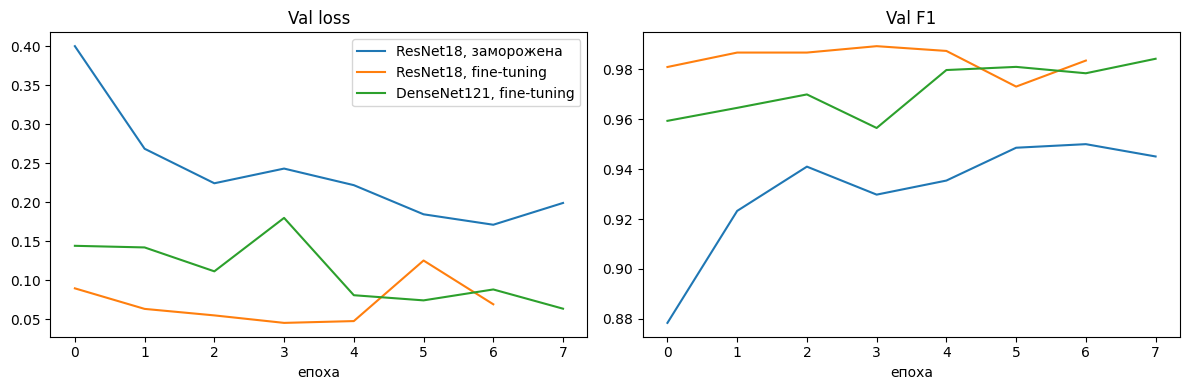

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for key, r in results.items():
    axes[0].plot(r["history"]["val_loss"], label=names[key])
    axes[1].plot(r["history"]["val_f1"], label=names[key])

axes[0].set_title("Val loss"); axes[0].set_xlabel("епоха"); axes[0].legend()
axes[1].set_title("Val F1");   axes[1].set_xlabel("епоха")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "transfer_curves.png", dpi=150)
plt.show()

Для fine-tuning моделей val loss нижчий, а F1 вищий вже з перших епох. Заморожена модель навчається повільніше і плавніше. Видно, що ці криві значно стабільніші, ніж у CNN з нуля.

### 10) Матриця помилок найкращої моделі

Вибираємо модель за найбільшим val F1 (не за test) і будуємо для неї матрицю помилок на test.

Найкраща за val F1: ResNet18, fine-tuning


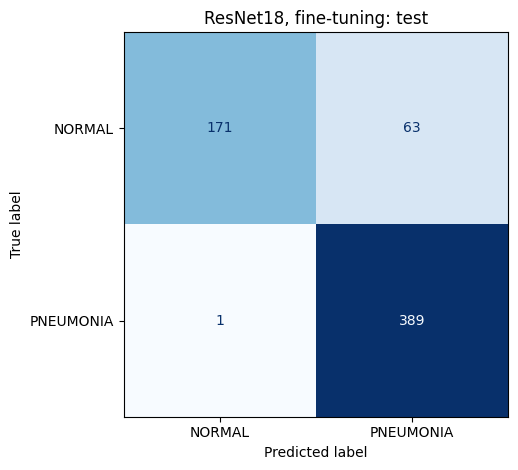

In [ ]:
best_key = max(results, key=lambda k: results[k]["val"]["f1"])
print("Найкраща за val F1:", names[best_key])

r = results[best_key]
cm = confusion_matrix(r["test_y"], (r["test_probs"] >= 0.5).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["NORMAL", "PNEUMONIA"]).plot(cmap="Blues", colorbar=False)
plt.title(f"{names[best_key]}: test")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "cm_transfer_best.png", dpi=150)
plt.show()

Найкращою за val F1 стала `ResNet18, fine-tuning` (0,989). На test вона пропускає лише 1 хворого з 390, але хибно позначає пневмонією 63 здорових з 234 (specificity 0,731).

### 11) Об'єднана таблиця всіх моделей

Об'єднуємо метрики з notebooks 02, 03 і 04 в одну таблицю `final_metrics.csv`. Для test сортуємо за accuracy. У рядках класичного ML і CNN з нуля AUC порожній (`NaN`), бо там його не рахували.

In [12]:
classical = pd.read_csv(RESULTS_DIR / "metrics_classical.csv")
cnn = pd.read_csv(RESULTS_DIR / "metrics_cnn.csv")

final = pd.concat([classical, cnn, metrics_tf], ignore_index=True)
final.to_csv(RESULTS_DIR / "final_metrics.csv", index=False)

final[final["split"] == "test"].drop(columns="split").sort_values("accuracy", ascending=False).round(3)

,model,accuracy,precision,recall,specificity,f1,auc
17,"ResNet18, fine-tuning",0.897,0.861,0.997,0.731,0.924,0.971
15,"ResNet18, заморожена",0.872,0.857,0.954,0.735,0.903,0.951
19,"DenseNet121, fine-tuning",0.862,0.823,0.992,0.645,0.900,0.966
13,CNN + аугментація + ваги,0.804,0.767,0.987,0.500,0.863,NaN
1,SVM (raw pixels),0.795,0.760,0.982,0.483,0.857,NaN
9,CNN + аугментація,0.779,0.744,0.985,0.436,0.848,NaN
3,SVM (HOG),0.769,0.731,0.997,0.389,0.844,NaN
11,CNN + ваги класів,0.744,0.711,0.992,0.329,0.829,NaN
5,Random Forest (HOG),0.742,0.712,0.987,0.333,0.827,NaN
7,CNN,0.710,0.683,1.000,0.226,0.812,NaN


Усі три моделі transfer learning стоять вище за класичний ML і CNN з нуля за test accuracy: ResNet18 fine-tuning 0,897, заморожена 0,872, DenseNet121 0,862 проти 0,71-0,80 в інших. Тобто готові ознаки з ImageNet допомагають, навіть коли знімки зовсім інші.

## Підсумок

**Що зроблено**
- Взяли ResNet18 і DenseNet121, попередньо навчені на ImageNet, і замінили в них останній шар.
- Порівняли три варіанти: заморожена ResNet18, ResNet18 з fine-tuning і DenseNet121 з fine-tuning.
- Використали різні `lr` для нового шару і готових блоків, аугментацію, ваги класів і раннє зупинення за val F1.
- Метрики зберегли в `metrics_transfer.csv`, об'єднану таблицю всіх моделей у `final_metrics.csv`.

**Висновки**
- Transfer learning краще за notebooks 02 і 03: test accuracy 0,86-0,90 проти 0,71-0,80.
- Fine-tuning кращий за заморожену модель, а велика DenseNet121 не дала переваги над ResNet18.
- Найкраща за val F1 і на test: ResNet18 fine-tuning (accuracy 0,897, recall 0,997, specificity 0,731).
- Specificity на test усе ще невисока: багато здорових знімків модель вважає хворими. 